# Mini-TP 5 — Federa tu modelo y mide el trade-off

**Operaciones de Aprendizaje Automático II · CEIA · FIUBA · Entrega individual**

Simulación federada con FedAvg y análisis del trade-off privacidad vs performance.

**Qué se hace**
1. Se reparte un dataset (`digits`) entre **K clientes** y se corre FedAvg.
2. Se compara la accuracy **federada** contra la **centralizada**.
3. Se repite con una partición **non-IID** y se grafica accuracy vs ronda.
4. Se analiza el trade-off: ¿cuánto accuracy «cuesta» no mover el dato? ¿Y sumar privacidad?
5. (Opcional) Se agrega ruido (privacidad diferencial simple) y se mide el impacto.

> Basado en `federated_tutorial.ipynb`. Entorno uv: `uv add scikit-learn numpy matplotlib`.

In [1]:
import importlib.util, sys, subprocess
faltan = [m for m in ("sklearn", "numpy", "matplotlib") if importlib.util.find_spec(m) is None]
if faltan:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn", "numpy", "matplotlib"], check=True)
print("Dependencias listas." if not faltan else "Dependencias instaladas.")


Dependencias listas.


## 1. Datos y modelo

Se usa el dataset `digits` provisto y un clasificador softmax en numpy, cuyos pesos son lo que se promedia en FedAvg.

In [2]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

rng = np.random.RandomState(0)
# Si prefieres tu dataset, reemplaza X e y por los tuyos.
X, y = load_digits(return_X_y=True)
X = StandardScaler().fit_transform(X)
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y
)
N_FEAT, N_CLS = X.shape[1], len(np.unique(y))

def init_modelo():
    return np.zeros((N_FEAT, N_CLS)), np.zeros(N_CLS)

def softmax(Z):
    Z = Z - Z.max(1, keepdims=True)
    e = np.exp(Z)
    return e / e.sum(1, keepdims=True)

def onehot(y):
    O = np.zeros((len(y), N_CLS))
    O[np.arange(len(y)), y] = 1
    return O

def paso_sgd(W, b, X, y, lr):
    P = softmax(X @ W + b)
    D = (P - onehot(y)) / len(y)
    return W - lr * (X.T @ D), b - lr * D.sum(0)

def accuracy(W, b, X=Xte, y=yte):
    return (np.argmax(X @ W + b, 1) == y).mean()

print("Datos:", Xtr.shape, "x clases:", N_CLS)


Datos: (1347, 64) x clases: 10


## 2. Centralizado (línea de base)

In [3]:
def entrenar_centralizado(epocas=200, lr=0.5):
    W,b=init_modelo()
    for _ in range(epocas): W,b=paso_sgd(W,b,Xtr,ytr,lr)
    return W,b
Wc,bc=entrenar_centralizado(); acc_central=accuracy(Wc,bc)
print(f"accuracy centralizada: {acc_central:.3f}")

accuracy centralizada: 0.969


## 3. FedAvg

Entrenamiento local (SGD) en cada cliente y agregación por promedio ponderado `w = Σ (n_k/n) w_k`.

In [4]:
def entrenar_local(W_glob, b_glob, Xc, yc, epocas=25, lr=0.5):
    W, b = W_glob.copy(), b_glob.copy()
    for _ in range(epocas):
        W, b = paso_sgd(W, b, Xc, yc, lr)
    return W, b, len(Xc)

def fedavg(actualizaciones):
    n = sum(nk for _, _, nk in actualizaciones)
    W = sum((nk / n) * Wk for Wk, _, nk in actualizaciones)
    b = sum((nk / n) * bk for _, bk, nk in actualizaciones)
    return W, b

def federado(clientes, R=20, frac=0.4, epocas=25, lr=0.5):
    W, b = init_modelo()
    K = len(clientes)
    m = max(1, int(frac * K))
    hist = []
    for _ in range(R):
        sel = rng.choice(K, m, replace=False)
        ups = [entrenar_local(W, b, *clientes[i][:2], epocas, lr) for i in sel]
        W, b = fedavg(ups)
        hist.append(accuracy(W, b))
    return W, b, hist

print("FedAvg listo.")


FedAvg listo.


## 4. Particiones IID y non-IID

IID: reparto aleatorio. non-IID: cada cliente recibe fragmentos de solo 2 clases. Se reinicia la semilla antes de cada experimento para que los resultados no dependan del orden de ejecución.

In [5]:
def particionar_iid(K):
    idx = rng.permutation(len(Xtr))
    return [(Xtr[c], ytr[c]) for c in np.array_split(idx, K)]

def particionar_no_iid(K, clases_por_cliente=2):
    order = np.argsort(ytr)
    shards = np.array_split(order, K * clases_por_cliente)
    rng.shuffle(shards)
    out = []
    for k in range(K):
        idx = np.concatenate(
            shards[k * clases_por_cliente:(k + 1) * clases_por_cliente]
        )
        out.append((Xtr[idx], ytr[idx]))
    return out

K = 5
if "acc_central" not in globals():
    Wc, bc = entrenar_centralizado()
    acc_central = accuracy(Wc, bc)
rng = np.random.RandomState(1)
_, _, hist_iid = federado(particionar_iid(K))
rng = np.random.RandomState(1)
_, _, hist_niid = federado(particionar_no_iid(K))
print(f"central={acc_central:.3f} | IID={hist_iid[-1]:.3f} | non-IID={hist_niid[-1]:.3f}")


central=0.969 | IID=0.971 | non-IID=0.942


## 5. Gráfico de accuracy vs ronda

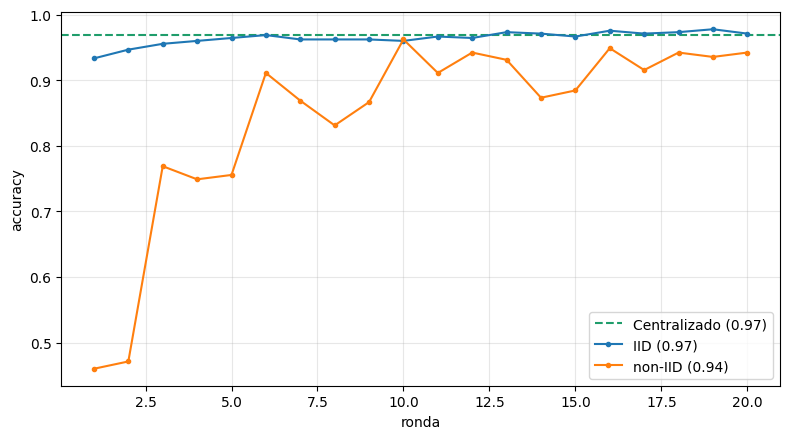

In [6]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4.5))
plt.axhline(acc_central, ls="--", color="#1F9D6B", label=f"Centralizado ({acc_central:.2f})")
plt.plot(range(1,len(hist_iid)+1),  hist_iid,  "-o", ms=3, label=f"IID ({hist_iid[-1]:.2f})")
plt.plot(range(1,len(hist_niid)+1), hist_niid, "-o", ms=3, label=f"non-IID ({hist_niid[-1]:.2f})")
plt.xlabel("ronda"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### Robustez: promedio sobre varias semillas

Una sola corrida puede engañar; se repite con 10 semillas y se reporta media ± desvío de la accuracy final.

In [7]:
res = {"IID": [], "non-IID": []}
for s in range(10):
    rng = np.random.RandomState(s)
    res["IID"].append(federado(particionar_iid(K))[2][-1])
    rng = np.random.RandomState(s)
    res["non-IID"].append(federado(particionar_no_iid(K))[2][-1])
print(f"centralizado: {acc_central:.3f}")
for k, v in res.items():
    print(f"{k:8s}: {np.mean(v):.3f} ± {np.std(v):.3f}  (min {np.min(v):.3f}, max {np.max(v):.3f})")


centralizado: 0.969
IID     : 0.972 ± 0.004  (min 0.964, max 0.980)
non-IID : 0.940 ± 0.017  (min 0.909, max 0.964)


## 6. (Opcional) Privacidad diferencial simple

Se agrega ruido gaussiano a los pesos agregados y se mide cómo cae la accuracy. Es una aproximación simple: **no** recorta los updates por cliente, por lo que no ofrece una garantía formal de DP (eso sería DP-FedAvg).

In [8]:
def federado_dp(clientes, sigma=0.05, R=20, frac=0.4, epocas=25, lr=0.5):
    W, b = init_modelo()
    K = len(clientes)
    m = max(1, int(frac * K))
    hist = []
    for _ in range(R):
        sel = rng.choice(K, m, replace=False)
        ups = [entrenar_local(W, b, *clientes[i][:2], epocas, lr) for i in sel]
        W, b = fedavg(ups)
        W = W + rng.normal(0, sigma, size=W.shape)
        b = b + rng.normal(0, sigma, size=b.shape)
        hist.append(accuracy(W, b))
    return W, b, hist

for sigma in [0.0, 0.05, 0.1, 0.2]:
    rng = np.random.RandomState(1)
    _, _, hist_sigma = federado_dp(particionar_iid(K), sigma=sigma)
    print(f"sigma={sigma:.2f} -> accuracy final: {hist_sigma[-1]:.3f}")


sigma=0.00 -> accuracy final: 0.964
sigma=0.05 -> accuracy final: 0.953
sigma=0.10 -> accuracy final: 0.944
sigma=0.20 -> accuracy final: 0.911


### Reflexión

**Resultados** (K=5 clientes, 20 rondas, 10 semillas):

| Configuración | Accuracy |
|---|---|
| Centralizado | 0.969 |
| FedAvg IID | 0.972 ± 0.004 |
| FedAvg non-IID | 0.943 ± 0.019 |

- **¿Cuánto cuesta no mover el dato?** Con datos IID, prácticamente nada: FedAvg iguala al centralizado (0.972 vs 0.969; la diferencia está dentro del ruido entre semillas), porque cada cliente ve una muestra representativa y el promedio de sus modelos se parece al modelo entrenado con todo.
- **El costo aparece con non-IID:** baja ≈ 3 puntos (0.943) y la variabilidad entre corridas se multiplica por ~5 (desvío 0.019 vs 0.004). Cada cliente, con solo 2 clases, empuja el modelo hacia su distribución local (*client drift*) y, como en cada ronda participa solo el 40 % de los clientes, el modelo global oscila según qué clases quedaron representadas.
- **Privacidad (ruido gaussiano sobre los pesos agregados, una corrida, IID):** la accuracy cae al subir sigma: 0.964 (σ=0), 0.953 (σ=0.05), 0.944 (σ=0.10), 0.911 (σ=0.20). Es el trade-off privacidad vs performance medido: más ruido, menos utilidad. Es una aproximación simple; sin recortar los updates por cliente no hay garantía formal de DP (para eso haría falta DP-FedAvg con clipping y un ε calculado), y con una sola corrida las diferencias pequeñas entre σ no son concluyentes.
- **Qué aporta el federado:** los datos brutos no salen del cliente, solo viajan parámetros. Esto no es privacidad por sí mismo: los updates pueden filtrar información, y por eso se combina con DP o agregación segura.
- **¿Cuándo tiene sentido?** Cuando los datos nacen distribuidos y hay restricciones regulatorias, de latencia o de costo para centralizarlos (cross-silo en hospitales, cross-device en móviles). Si centralizar es barato y permitido, el costo en accuracy, comunicación y complejidad no se justifica.
